In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [2]:
sos = np.load('/afs/jiajiwei-folder/wangjt/datasets/openfwi/CurveFault_B/vel6_1_0.npy')
sosA = np.load('/afs/jiajiwei-folder/wangjt/datasets/openfwi/CurveVel_A/model/model1.npy')
sosFlatA = np.load('/afs/jiajiwei-folder/wangjt/datasets/openfwi/FlatVel_A/model/model1.npy')

In [3]:
sos = torch.from_numpy(np.array(sos)) # [N, 1, 70, 70]
sos = torch.nn.functional.interpolate(sos, size=(256, 256), mode='bilinear', align_corners=False)

sosA = torch.from_numpy(np.array(sosA)) # [N, 1, 70, 70]
sosA = torch.nn.functional.interpolate(sosA, size=(256, 256), mode='bilinear', align_corners=False)

sosFlatA = torch.from_numpy(np.array(sosFlatA)) # [N, 1, 70, 70]
sosFlatA = torch.nn.functional.interpolate(sosFlatA, size=(256, 256), mode='bilinear', align_corners=False)

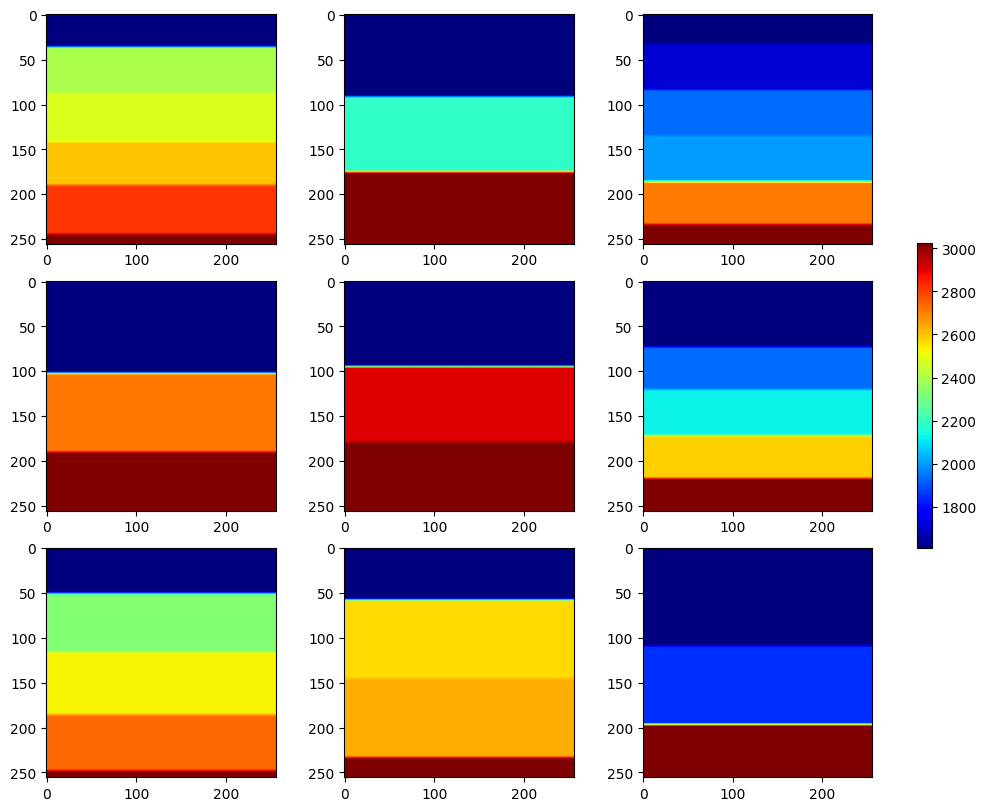

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8), constrained_layout=True)

for i in range(9):
    ax = axes[i // 3, i % 3]
    im = ax.imshow(sosFlatA[i, 0].cpu(), cmap='jet')
    # ax.axis('off')

fig.colorbar(im, ax=axes, shrink=0.4)
plt.show()

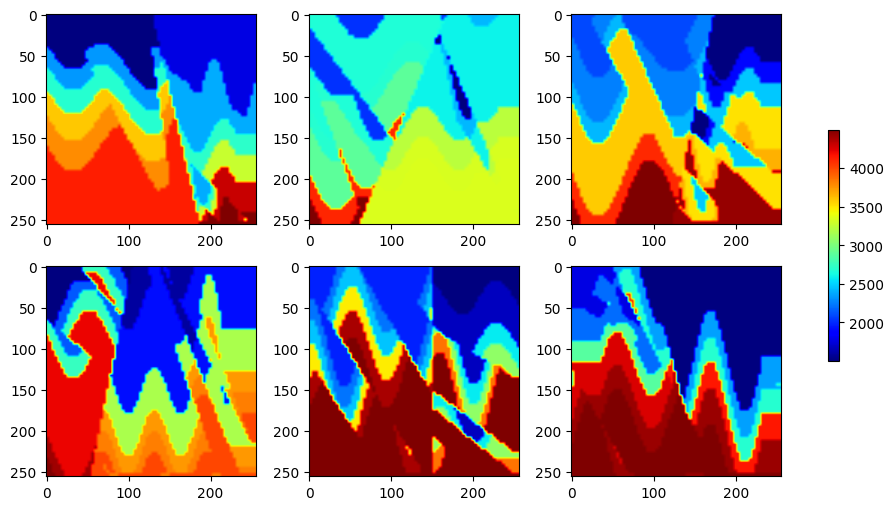

In [31]:

fig, axes = plt.subplots(2, 3, figsize=(12, 6),)

for i in range(6):
    ax = axes[i // 3,  i % 3]
    im = ax.imshow(sos[i*50, 0].cpu(), cmap='jet')  # 可根据需要换 colormap
    # ax.set_title(f'sos[{i}]')
    # plt.colorbar(im, ax=ax, shrink=0.7)
fig.colorbar(im, ax=axes, shrink=0.5)
# plt.tight_layout()
plt.savefig("openfwi_curvefault_B.png")

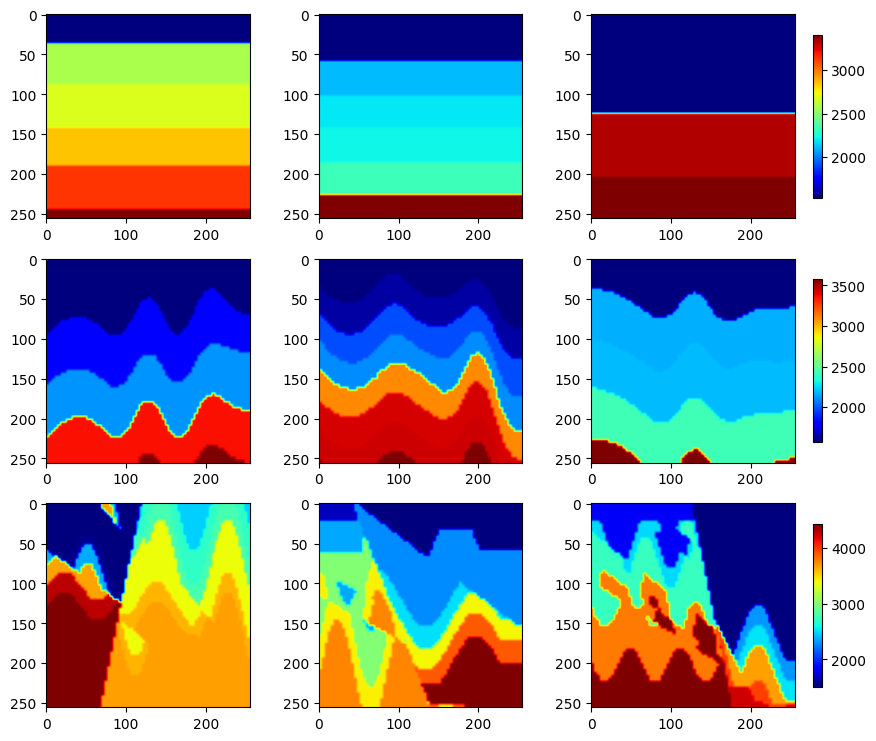

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9),)


for i in range(9):
    ax = axes[i // 3,  i % 3]
    if i<3:
        im1 = ax.imshow(sosFlatA[i*10, 0].cpu(), cmap='jet')  # 可根据需要换 colormap
    elif i<6:
        im2 = ax.imshow(sosA[i*10, 0].cpu(), cmap='jet')
    else:
        im3 = ax.imshow(sos[i*50, 0].cpu(), cmap='jet')
    # ax.set_title(f'sos[{i}]')
fig.colorbar(im1, ax=axes[0], shrink=0.8, pad=0.02)
fig.colorbar(im2, ax=axes[1], shrink=0.8, pad=0.02)
fig.colorbar(im3, ax=axes[2], shrink=0.8, pad=0.02)
plt.savefig("openfwi_flatvel_A_and_curvevel_A_and_curvefault_B.png")

In [2]:
sos = np.load('/home/wangjt/work/datasets/ai4scup/speed/train_1.npy')
sos.shape

(480, 480)

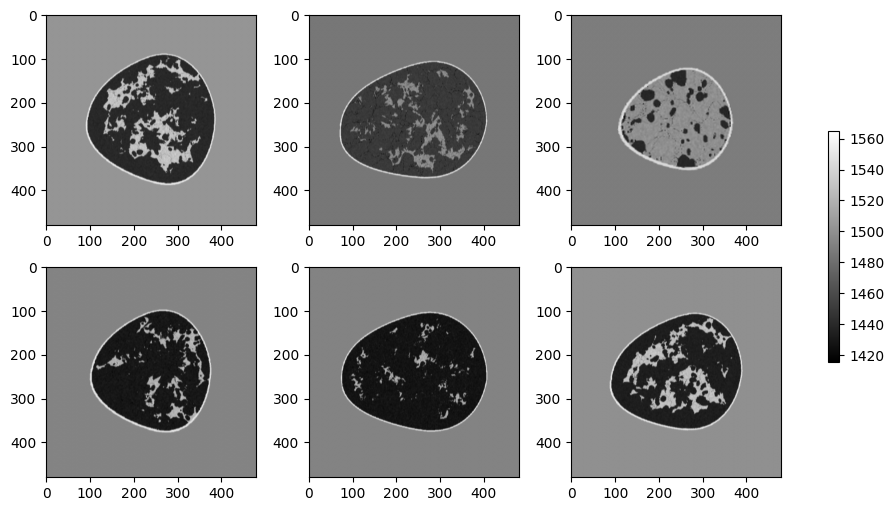

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6),)

for i in range(6):
    ax = axes[i // 3, i % 3]
    sos_data = np.load(f'/home/wangjt/work/datasets/ai4scup/speed/train_{i*900+1}.npy')
    im = ax.imshow(sos_data, cmap='gray')
    # ax.axis('off')

fig.colorbar(im, ax=axes, shrink=0.5)
plt.savefig('openwaves_breast.png')

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [41]:
FILE_PATH = '/home/wangjt/work/MPMG/outputs/3d/openfwi/mpmg_bs/wavefield/u_mpmg3d_bs_6001.pth'
FILE_PATH = "/home/wangjt/work/MPMG/outputs/3d/openfwi/cbs/wavefield/u_cbs_6001.pth"
model = torch.load(FILE_PATH).numpy()[0, 0]

In [42]:
model.shape

(224, 224, 224)

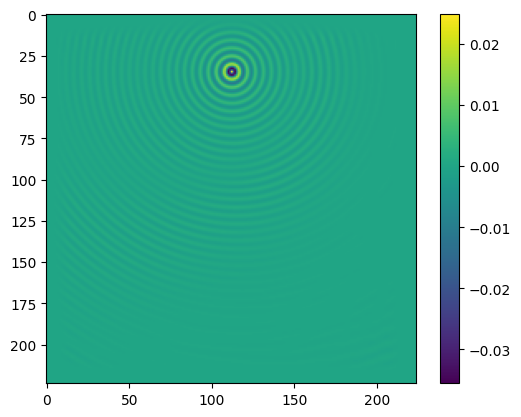

In [43]:
plt.imshow(model[:,:,111].real)
plt.colorbar()

In [46]:
(model.real).max()

np.float64(0.17037402322934586)

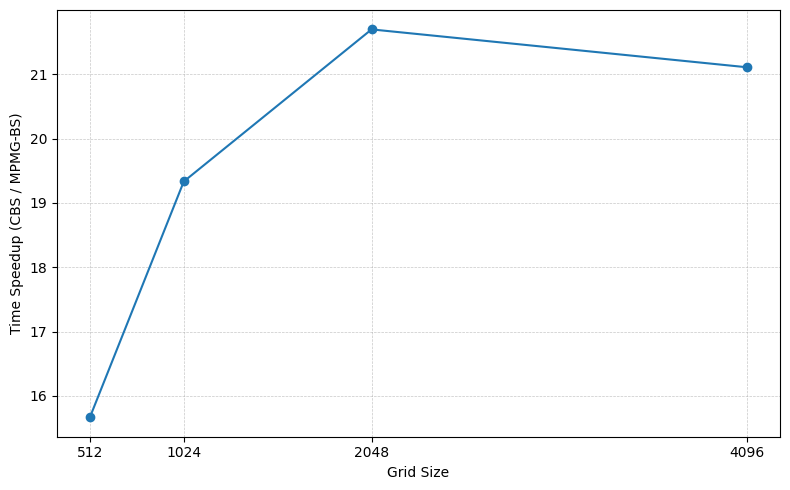

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# 数据：分辨率和对应的时间（单位：秒）
resolutions = [512, 1024, 2048, 4096]
mpmg_bs_time = [0.03, 0.09, 0.53, 5.59]
cbs_time = [0.47, 1.74, 11.5, 118.0]

# 计算加速比：CBS 时间 / MPMG-BS 时间
speedup = np.array(cbs_time) / np.array(mpmg_bs_time)

# 绘图
plt.figure(figsize=(8, 5))
plt.plot(resolutions, speedup, marker='o', linestyle='-', label='Speedup (CBS / MPMG-BS)')

# 添加数值标签
# for i, res in enumerate(resolutions):
#     plt.text(res, speedup[i], f"{speedup[i]:.1f}x", fontsize=10, ha='center', va='bottom')

# 设置横轴为对数刻度，因为分辨率是指数增长
# plt.xscale('log')

# 标签和标题
plt.xlabel('Grid Size', fontsize=10)
plt.ylabel('Time Speedup (CBS / MPMG-BS)', fontsize=10)
# plt.title('Time Speedup of MPMG-BS over CBS across Grid Sizes')
plt.xticks(resolutions, [f'{r}' for r in resolutions])  # 显示为 NxN
plt.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

# 显示图例
# plt.legend()

# 调整布局并显示
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from dataloader import unspvd_sos_Dataset

In [18]:
dataset = unspvd_sos_Dataset(sos_path='/home/wangjt/work/datasets/Marmousi/vp.bin',data_size=256,data_type='marmousi',data_num=100)

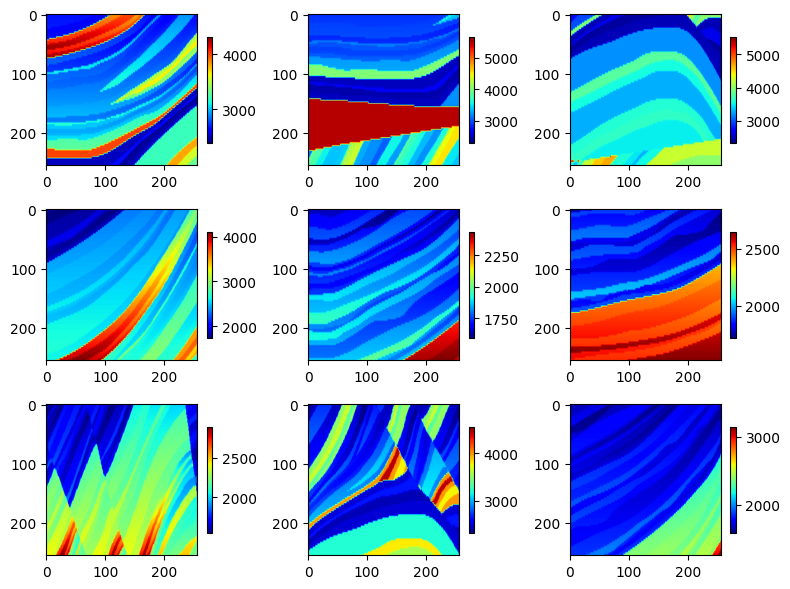

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8), constrained_layout=True)

for i in range(9):
    ax = axes[i // 3, i % 3]
    im = ax.imshow(sos[i, 0].cpu(), cmap='jet')
    ax.axis('off')

fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

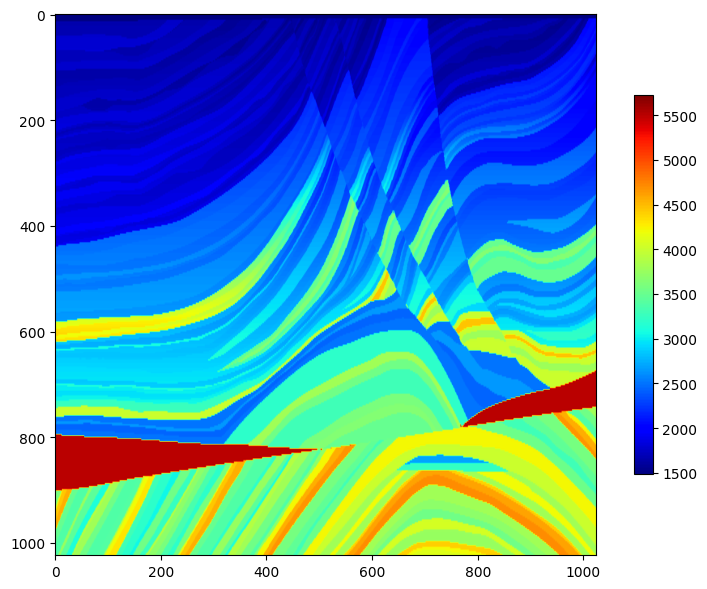

In [ ]:
dataset = unspvd_sos_Dataset(sos_path='/home/wangjt/work/datasets/Marmousi/vp.bin',data_size=1024,data_type='marmousi',data_num=100)
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

im = ax.imshow(dataset[0][0].cpu(), cmap='jet')
plt.colorbar(im, ax=ax, shrink=0.7)

# 可选：添加标题
# ax.set_title('sos[0]')

plt.tight_layout()
plt.show()